# Petróleo e inflação no Brasil
**EAD6034 · Rafael Palazzi · Renan de Luca Avila**

A pergunta é se uma mesma alta inesperada do petróleo tem uma resposta diferente no IPCA antes e depois de outubro de 2016. Vamos construir a resposta em **seis células de código**, mantendo explicação, gráficos e tabelas nesta página.

## 1. Definir as condições do experimento
Execute cada célula com **Shift+Enter**. Os gráficos aparecem abaixo da célula. Para comparar outro cenário, altere os parâmetros aqui e use **Restart Kernel and Run All Cells**; assim nenhum resultado antigo é reutilizado por engano.

O arquivo `analise.py` reúne as rotinas técnicas. Importá-lo não executa a análise. As células abaixo chamam etapas com nomes diretos. Você só precisa editar este painel durante a apresentação.

<details><summary>Todos os parâmetros: valores de referência, razões e efeitos das mudanças</summary>

Os parâmetros herdados também estão no dicionário `PARAMETROS`. Para mudar qualquer um, acrescente seu nome à chamada `PARAMETROS.update(...)` antes de `configurar`.

| Parâmetro | Valor de referência | Razão / efeito |
|---|---|---|
| `INICIO` | `"2004-01-01"` | Início da tarefa. Avançar reduz informação histórica. |
| `FIM` | `"2026-09-01"` | Fotografia dos dados. 2023-04-01 evita misturar a mudança de 2023. |
| `QUEBRA` | `"2016-10-01"` | Primeiro mês do segundo regime. Experimente 2018-01-01. |
| `ORDEM` | `["brent", "cambio", "ipa", "ipca", "selic"]` | Anteriores afetam posteriores no mesmo mês. |
| `ORDEM_ALT` | `["cambio", "brent", "ipa", "selic", "ipca"]` | Hipótese alternativa de reação no mês. |
| `P_FIXO` | `None` | None seleciona p. Inteiro força p: experimente 1, 2 ou 4. |
| `P_MAX` | `6` | Teto parcimonioso: 5 variáveis custam 25 coeficientes por lag. |
| `CRITERIO` | `"bic"` | BIC penaliza tamanho; "aic" ou "hq" permitem mais persistência. |
| `AJUSTAR_P_RESIDUOS` | `True` | Tenta p >= escolhido até passar Portmanteau, limitado a P_MAX. |
| `SAZONAIS` | `True` | 11 indicadores mensais. False deixa sazonalidade nos resíduos. |
| `DUMMIES` | `True` | Pulsos isolam episódios extremos sem apagar meses. |
| `MESES_ATIPICOS` | `["2018-05", "2018-06", "2020-03", "2020-04", "2020-05", "2020-06"]` | Lista de meses de greve/pandemia usada nos pulsos. |
| `EXCLUIR_2020` | `False` | Retira equações/defasagens que tocam 2020; não cola 2019 em 2021. |
| `DIFERENCIAR_SELIC` | `False` | Nível segue a aula. True testa sensibilidade à raiz unitária. |
| `H` | `24` | Horizonte IRF. Aumentar amplia incerteza e custo. |
| `H_REPASSE` | `12` | Acumulação h=0 até h=12, inclusive. |
| `CHOQUE_PCT` | `10.0` | Alta exata de 10%: impacto em log = 100*log(1.10). |
| `CONFIANCA` | `0.90` | Bandas pontuais como na aula. 0.95 alarga as bandas. |
| `BOOT` | `399` | Wild bootstrap: 99 para ensaio rápido, 999 para mais precisão. |
| `SEMENTE` | `20261025` | Reprodutibilidade. Mudar altera apenas erro Monte Carlo. |
| `ALFA` | `0.05` | Limiar dos testes, distinto de CONFIANCA das IRFs. |
| `LAG_DIAG` | `12` | Autocorrelação até um ano, sempre deve superar p. |
| `LAG_ARCH` | `4` | ARCH por equação: janela curta para limitar parâmetros. |
| `LAG_HAC` | `12` | Newey-West/Bartlett: autocovariâncias até 12 meses. |
| `CUSUM_INICIAL` | `36` | Aquecimento mínimo de 3 anos; maior valor atrasa o diagnóstico. |
| `REG_TESTES` | `"c"` | Constante, sem tendência nas taxas. "ct" admite tendência e muda H0. |
| `ADF_CRITERIO` | `"BIC"` | Escolhe lags do teste ADF, independentemente do critério do VAR. |
| `KPSS_LAGS` | `"auto"` | Largura automática; inteiro fixa a correção de dependência. |
| `MIN_GRAUS_LIVRES` | `10` | Margem mínima para estimar variância. Aumentar exige mais dados. |
| `THREADS` | `1` | Definido ao importar analise.py; altere lá antes de iniciar o kernel. Uma thread basta. |
| `ADF_MAX` | `12` | ADF até um ano, seleção BIC; KPSS usa largura automática. |
| `D_MAX` | `1` | Toda-Yamamoto: 1 lag extra não testado, admite variáveis I(1). |
| `JANELA` | `96` | Repasse móvel em 8 anos. Menor janela aumenta imprecisão. |
| `PASSO_JANELA` | `3` | Reestima a cada trimestre por velocidade; 1 gera curva mensal. |
| `FEVD_H` | `[1, 12, 24]` | h passos soma inovações de 0 a h-1, convenção da FEVD. |
| `EPISODIO` | `("2021-01-01", "2022-12-01")` | Episódio da decomposição histórica. |
| `INICIO_PREV` | `"2017-01-01"` | Primeira origem, treino até esse mês. Mais cedo amplia avaliação. |
| `H_PREV` | `[1, 12]` | Inflação DO MÊS t+h, não inflação acumulada dos h meses. |
| `SIM_N` | `600` | Observações simuladas; mais dados aproximam parâmetros verdadeiros. |
| `SIM_DESCARTE` | `200` | Aquecimento para reduzir influência da condição inicial. |
| `SIM_A` | `[[0.6, 0, -0.2], [0.15, 0.5, -0.1], [0.1, 0.2, 0.7]]` | Dinâmica conhecida, estável. |
| `SIM_P` | `[[1, 0, 0], [0.3, 0.7, 0], [0.5, 0.4, 0.6]]` | Impacto recursivo, zeros são hipóteses. |
| `PAUSAR` | `True` | Só no terminal. No notebook, a própria célula faz a pausa. |
| `MOSTRAR` | `True` | Só no terminal. O notebook força a exibição inline. |
| `PASTA_SAIDA` | `"resultados"` | Use resultados_teste para preservar os resultados de referência. |
| `DPI` | `150` | Qualidade PNG, sem efeito estatístico. |
| `FONT_SIZE` | `11` | Letras dos gráficos, sem efeito estatístico. |
| `MAX_LINHAS_TELA` | `24` | Limita tabelas longas em cada saída; CSV sempre contém tudo. |
| `CASAS` | `4` | Arredondamento na tela; CSV mantém precisão. |
| `TOL` | `1e-8` | Tolerância numérica das checagens, não significância. |

</details>


In [1]:
from copy import deepcopy
import analise as var
%matplotlib inline

# Todos os controles ficam neste dicionário; a tabela acima documenta os demais.
PARAMETROS = deepcopy(var.PARAMETROS_PADRAO)
PARAMETROS.update(
    P_FIXO=None,                 # BIC automático; 4 usa mais memória e reduz graus de liberdade.
    QUEBRA="2016-10-01",         # Início do segundo regime; trocar muda a comparação histórica.
    FIM="2026-09-01",            # 2023-04-01 retira a estratégia posterior de preços.
    ORDEM=["brent", "cambio", "ipa", "ipca", "selic"],  # Quem pode reagir no mesmo mês.
    CHOQUE_PCT=10.0,             # Alta única no impacto; maior valor escala a resposta.
    H_REPASSE=12,                # Soma do impacto até o mês 12, incluindo ambos.
    BOOT=399,                   # 99 acelera o ensaio; mais réplicas refinam os quantis.
    CONFIANCA=0.90,              # 0.95 produz bandas mais amplas.
    SAZONAIS=True,              # Controla o padrão mensal; False o deixa na dinâmica/resíduos.
    DUMMIES=True,               # Pulsos para greve e pandemia; False os atribui ao VAR.
    EXCLUIR_2020=False,          # True retira também equações com defasagens em 2020.
    DIFERENCIAR_SELIC=False,     # True troca o nível pela variação da taxa.
    PASTA_SAIDA="resultados",    # Use resultados_teste para preservar a referência.
)
var.configurar(PARAMETROS, notebook=True)


## 2. Entender as cinco séries
Lemos os dados públicos salvos junto do notebook. Não há download durante a apresentação.

**Brent** é o petróleo em dólares. **Câmbio** é R$/US$, de modo que uma alta significa depreciação do real. Ambos entram como variações do log. **IPA-DI** e **IPCA** já são taxas mensais; a **Selic** entra em nível anualizado na base. O eixo vertical de cada painel informa a unidade, e o horizontal informa o mês.

Na tabela seguinte, o ADF testa raiz unitária e o KPSS testa estacionariedade. Observe a dúvida sobre a Selic, em vez de escolher apenas o teste conveniente.


### 1. Dados: cinco séries mensais, públicas e salvas no repositório

01/2004 a 09/2026: 273 meses. Ordem: ['brent', 'cambio', 'ipa', 'ipca', 'selic']


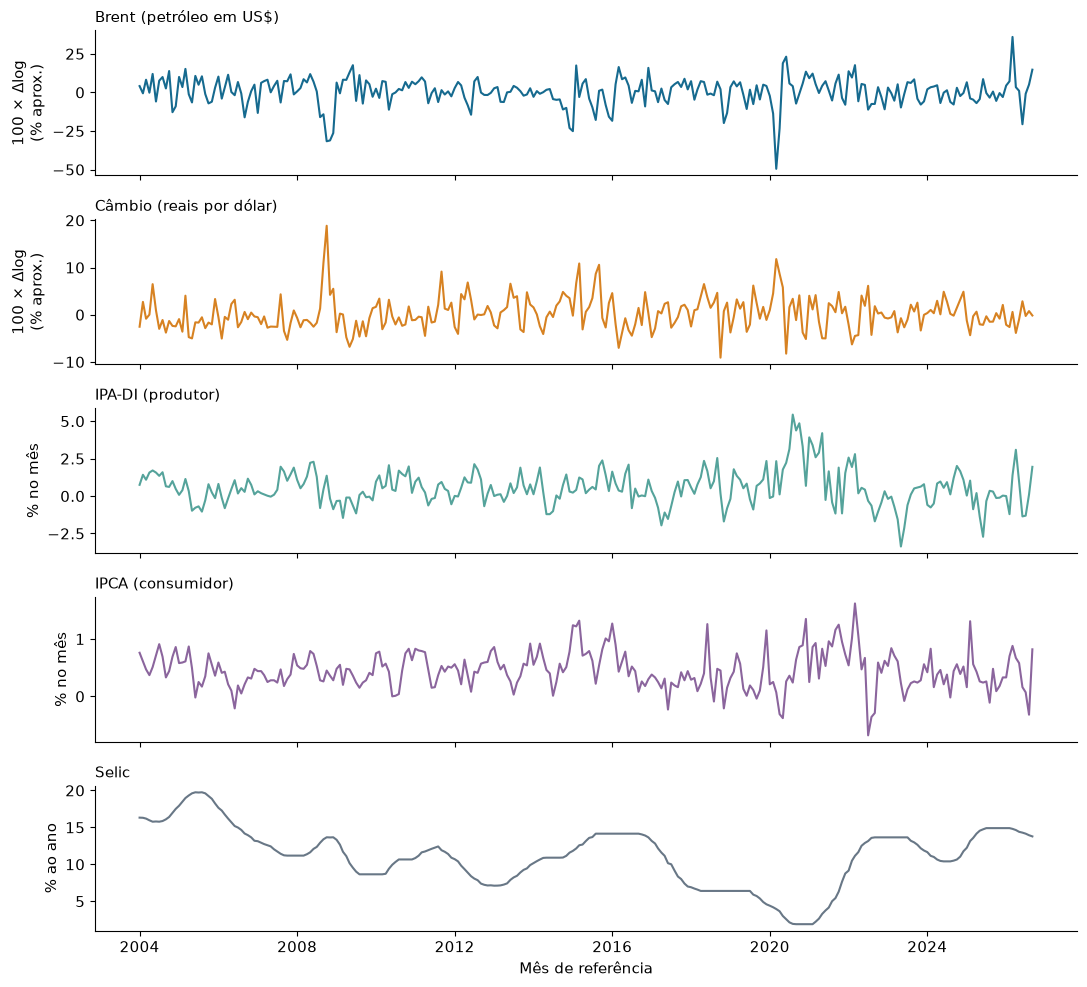

**01 estacionariedade**

,ADF_p,KPSS_p
serie,,
brent,0.0000,0.10
cambio,0.0000,0.10
ipa,0.0000,0.10
ipca,0.0000,0.10
selic,0.0745,0.03
log_Brent_nivel,0.0044,0.10
log_cambio_nivel,0.8762,0.01


ADF: H0 raiz unitária. KPSS: H0 estacionariedade. P-valores de fronteira são limites.


In [2]:
# Os gráficos e a tabela de estacionariedade aparecem aqui.
dados = var.carregar_dados()


## 3. Aprender a dinâmica antes e depois de 2016
O VAR usa o passado das cinco séries para explicar cada uma delas. O BIC escolhe quantos meses de memória usar; aumentar esse número custa observações e parâmetros.

Estimamos um modelo em **jan/2004 a set/2016** e outro em **out/2016 a set/2026**, na configuração de referência. Os dois usam o mesmo número de defasagens, com coeficientes reestimados. A data de quebra e o fim da amostra podem ser alterados no painel.

**O que observar:** raízes dentro do círculo indicam estabilidade estimada, mas não garantem resíduos adequados. O Portmanteau ainda rejeita ausência de autocorrelação na base. Granger pergunta se o passado de uma variável acrescenta informação preditiva; isso não prova causalidade econômica.


### 2. Escolha de p, resíduos e estabilidade dinâmica

**02 defasagens**

,aic,bic,hq,p_autocorr
p,,,,
1,1.3335,2.8786,1.9542,0.0
2,0.3463,2.2273,1.1019,0.0
3,0.2689,2.4857,1.1594,0.0
4,0.3237,2.8764,1.3491,0.0
5,0.3092,3.1978,1.4695,0.0
6,0.4012,3.6257,1.6965,0.0


**02 residuos completa**

,JB_p,ARCH_p
brent,0.0022,0.0150
cambio,0.0000,0.0543
ipa,0.0919,0.0001
ipca,0.0000,0.2169
selic,0.0000,0.0000


**02 residuos antes**

... (4 outputs left out)

,n,k_por_eq,p,raio,meia_vida,Portmanteau_p
amostra,,,,,,
completa,271,28,2,0.9127,7.5852,0.000
antes,151,22,2,0.9199,8.3056,0.002
depois,118,28,2,0.9224,8.5844,0.000


**02 ciclos**

,modulo,periodo_meses
0,0.9127,218.0132
1,0.4445,4.5636
2,0.2012,2.9401
3,0.5087,98.7917


Meia-vida: modo dominante, não necessariamente a meia-vida de cada IRF.
RESSALVA: autocorrelação residual. Bootstrap e p-valores exigem cautela; teste outro p.


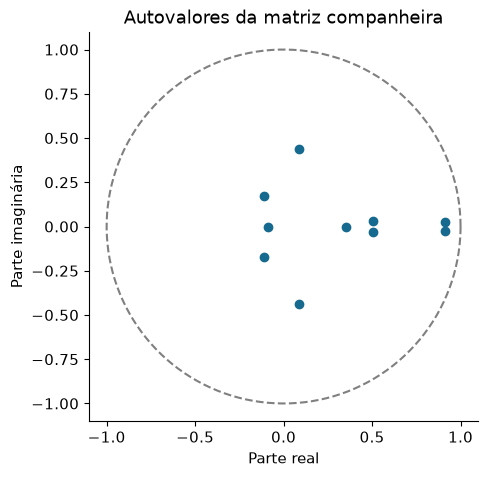

### 3. Granger condicional, usual e robusto HAC

**03 granger**

,causa,destino,Wald_usual_p,Wald_HAC_p
0,brent,cambio,0.0871,0.2159
1,brent,ipa,0.0023,0.0096
2,brent,ipca,0.0410,0.0107
3,brent,selic,0.2012,0.1031
4,cambio,brent,0.0021,0.0222
5,cambio,ipa,0.0141,0.0017
6,cambio,ipca,0.0953,0.2174
7,cambio,selic,0.5731,0.5054
8,ipa,brent,0.3674,0.2039
9,ipa,cambio,0.0099,0.0001


VAR aumentado p+dmax=3; testamos p=2. dmax=1 deve cobrir a integração.


In [3]:
# Primeiro, o modelo e seus diagnósticos; depois, informação preditiva condicional.
modelo, regimes, diagnostico = var.estimar_modelos(dados)
_ = var.testar_granger(dados, modelo.p)


## 4. Fazer o experimento e interpretar a resposta
**Experimento principal:** no mês do impacto, aplicamos uma surpresa que aumenta o **Brent em US$ em 10%**. É uma alta única no impacto, e não uma alta de 10% em todos os meses.

Dentro de cada regime, comparamos duas trajetórias: **com essa surpresa** e **sem essa surpresa**, mantendo iguais as condições iniciais e os controles. As demais surpresas são zeradas. Câmbio, IPA, IPCA e Selic **podem reagir endogenamente**, conforme o VAR e a ordem contemporânea escolhida.

A curva mostra a diferença acumulada do IPCA entre essas trajetórias. Somamos o impacto (h=0) até o mês 12, inclusive: **13 termos**. Como o IPCA entra como taxa simples, a soma é uma aproximação em pontos percentuais de inflação acumulada.

O painel da direita faz **outro experimento, separado**: uma surpresa que aumenta R$/US$ em 10%, isto é, deprecia o real. Não estamos aplicando simultaneamente os dois choques.

**Leitura da base:** para o Brent, cerca de +0,07 p.p. antes e +0,41 p.p. depois. A diferença é +0,34 p.p. Compare a banda da **diferença** com zero. As bandas de 90% são condicionais às hipóteses do modelo; a autocorrelação residual limita sua interpretação. Após mudar parâmetros, releia os novos valores, não esta referência.


### 4. Resposta do IPCA ao Brent e ao câmbio, antes e depois da quebra

antes 399 réplicas; 0.0% com raiz >= 1


depois 399 réplicas; 0.3% com raiz >= 1


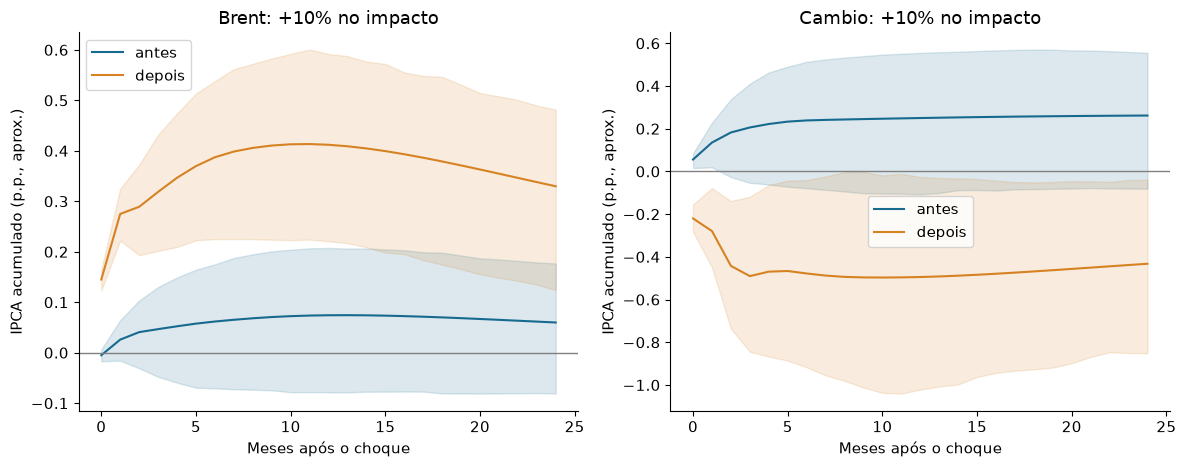

**04 respostas 12m**

,choque,amostra,resposta,inferior,superior
0,brent,antes,0.0742,-0.0783,0.2076
1,brent,depois,0.4120,0.2209,0.5918
2,cambio,antes,0.2501,-0.1073,0.5550
3,cambio,depois,-0.4944,-1.0217,-0.0262


**04 diferenca**

,depois_menos_antes,inferior,superior
brent,0.3378,0.1003,0.5757
cambio,-0.7445,-1.3330,-0.1389


Compare a banda da DIFERENÇA com zero. Sobreposição de bandas separadas não é um teste.


**04 razao antes**

,elasticidade_aprox,inferior,superior,denominador_cruza_zero
brent,0.0053,-0.0059,0.0166,False
cambio,0.0193,-0.0081,0.0434,False


**04 razao depois**

,elasticidade_aprox,inferior,superior,denominador_cruza_zero
brent,0.0409,0.0242,0.0601,False
cambio,-0.0581,-0.1119,-0.0033,False


In [4]:
# Esta é a célula central da apresentação: mesmo choque, dois regimes.
choques = var.comparar_choques(regimes)


## 5. Verificar se a história depende das hipóteses
O envelope reúne **120 ordenações**. É uma faixa de sensibilidade, não um intervalo de confiança. A FEVD reparte a variância do erro de previsão entre choques. A comparação com covariância comum distingue mudanças na propagação de mudanças nos impactos contemporâneos.

Chow testa estabilidade na data conhecida e CUSUM acompanha mudanças ao longo da amostra. No gráfico de repasse móvel, cada ponto usa uma janela de **96 meses de dados** para calcular um repasse até h=12. A **linha vertical tracejada marca outubro/2016**, o início do regime pós-quebra; sua data acompanha o parâmetro `QUEBRA`.

**Experimento ao vivo:** volte ao painel, coloque `P_FIXO=4`, `BOOT=99` e `PASTA_SAIDA="resultados_teste"`, e reexecute. A diferença do petróleo continua positiva no ensaio, mas a banda passa a incluir zero. Isso limita a força da conclusão.


### 5. Todas as 120 ordenações e FEVD

**05 correlacao residuos**

,brent,cambio,ipa,ipca,selic
brent,1.0000,-0.2992,0.2436,0.1657,-0.0661
cambio,-0.2992,1.0000,0.1951,-0.0862,-0.0722
ipa,0.2436,0.1951,1.0000,0.2860,0.0450
ipca,0.1657,-0.0862,0.2860,1.0000,0.1192
selic,-0.0661,-0.0722,0.0450,0.1192,1.0000


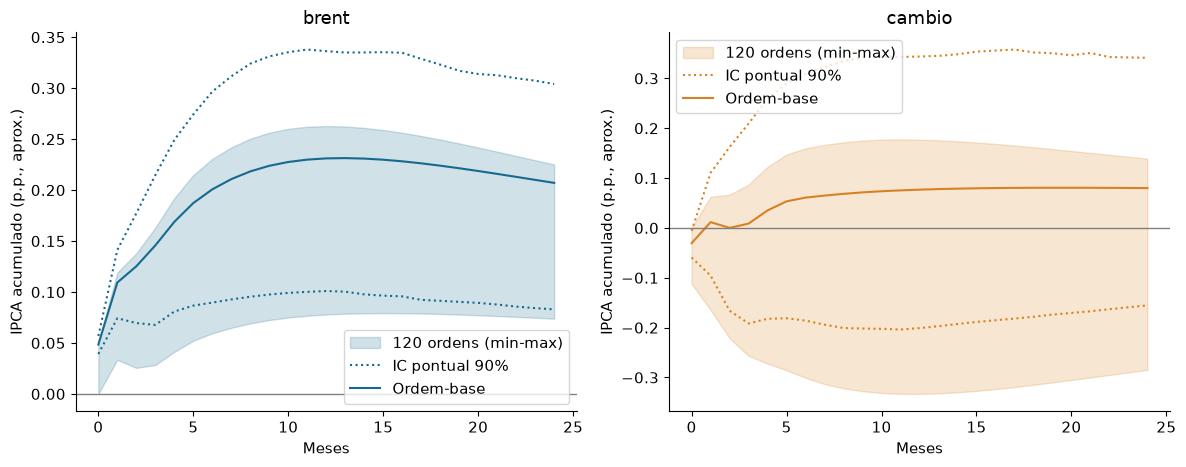

Envelope: sensibilidade à identificação, NÃO intervalo de confiança.


**05 mudanca 120 ordens**

,min_delta,max_delta,fracao_delta_positivo
brent,0.0338,0.3378,1.0
cambio,-0.8077,-0.1913,0.0


**05 fevd ipca**

,ordem,h,brent,cambio,ipa,ipca,selic
0,base,1,2.7448,0.1476,7.6292,89.4783,0.0000
1,base,12,6.6185,0.4538,16.7644,72.3934,3.7699
2,base,24,6.5593,0.4473,16.6532,71.4180,4.9221
3,alternativa,1,2.1489,0.7436,7.6292,88.4510,1.0273
4,alternativa,12,6.4529,0.6194,16.7644,70.6262,5.5371
5,alternativa,24,6.3925,0.6142,16.6532,69.6006,6.7395


**05 propagacao covariancia comum**

... (3 outputs left out)

,Chow_F_p,Wald_HAC_p
equacao,,
brent,0.4679,0.1163
cambio,0.0115,0.0027
ipa,0.0357,0.0008
ipca,0.0227,0.0010
selic,0.8422,0.2918


**06 quebra conjunta**

,LR,restricoes,p_assintotico
0,91.8461,55,0.0013


11 restrições/equação; 55 no sistema. LR supõe covariância comum; inferência exploratória em níveis.


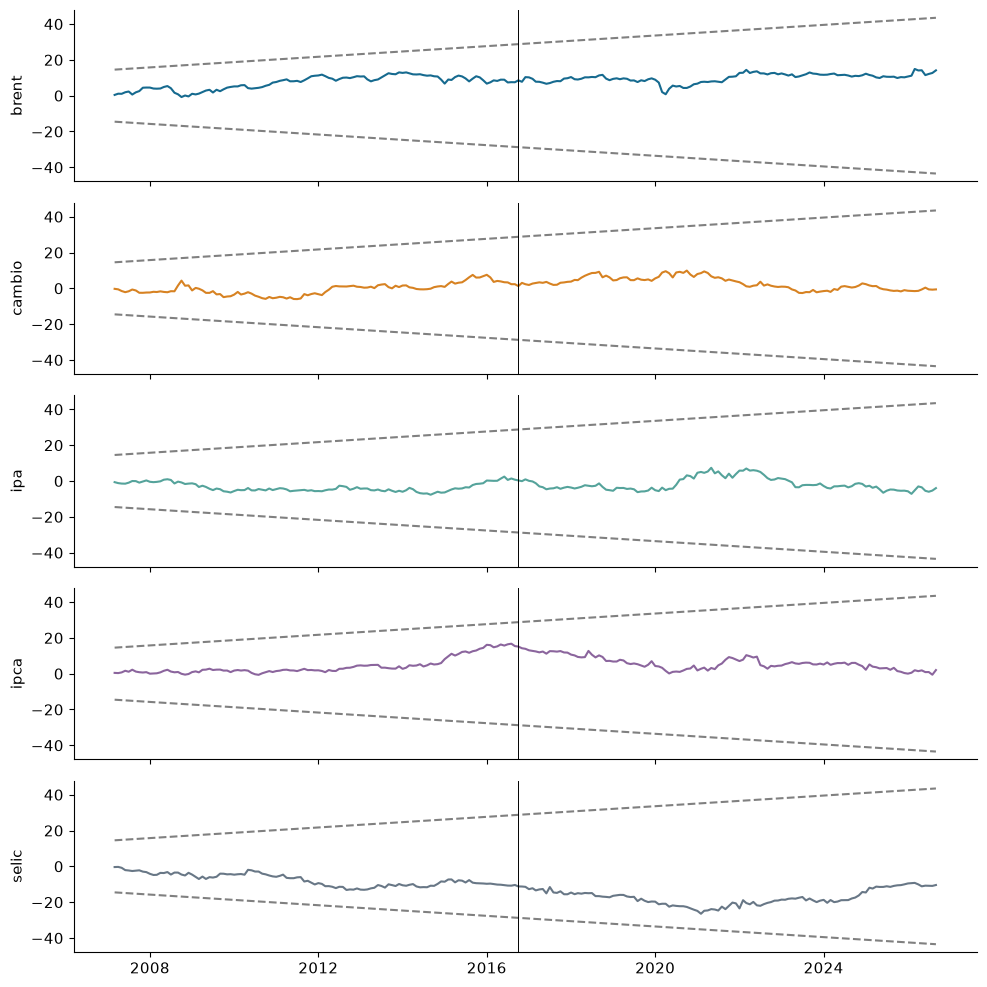

**06 repasse movel**

,brent,cambio,raio
data,,,
2011-12-01,0.0219,-0.0011,0.9231
2012-03-01,0.0230,-0.0026,0.9247
2012-06-01,0.0184,-0.0213,0.9293
2012-09-01,0.0169,-0.0067,0.8833
2012-12-01,0.0179,-0.0041,0.8789
2013-03-01,0.0149,0.0007,0.8593
2013-06-01,0.0152,0.0023,0.8581
2013-09-01,0.0099,0.0090,0.8776
2013-12-01,0.0108,0.0094,0.8830


[Linhas intermediárias omitidas na tela; arquivo CSV completo.]


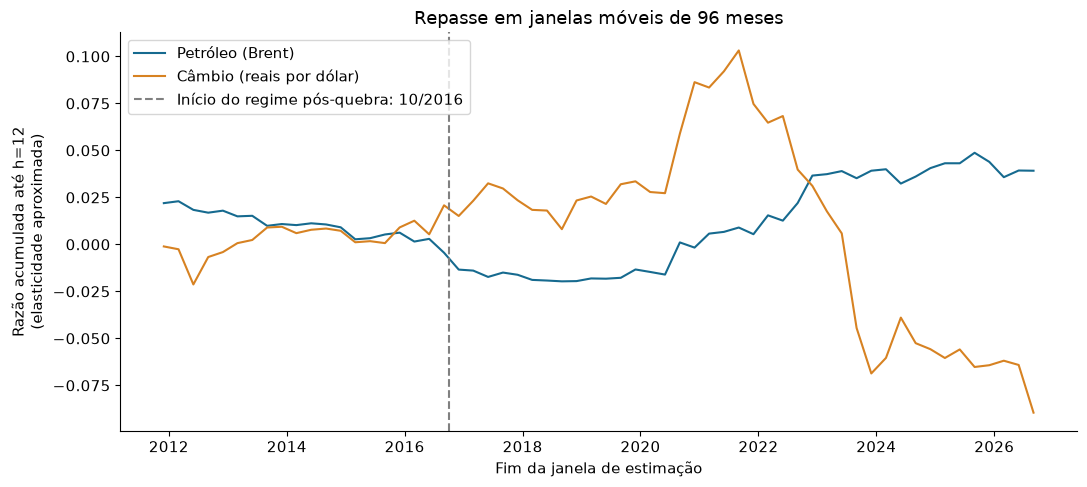

CUSUM sem pulsos: episódios extremos também podem provocar rejeição. Janelas se sobrepõem.


In [5]:
# Todas as verificações e seus gráficos ficam na saída desta célula.
_ = var.verificar_robustez(dados, modelo, regimes, choques)


## 6. Reconstruir a história, simular e avaliar previsão
A decomposição histórica reconstrói o IPCA como base determinística mais contribuições dos choques. A linha do gráfico é o IPCA **menos a base**, para que possa ser comparada à soma das barras.

Na simulação, conhecemos a verdade e mostramos o que uma ordenação errada faz com a resposta estimada. Depois, avaliamos previsão com treino expansivo e sem dados posteriores à origem. O alvo é o IPCA **do mês t+1 ou t+12**, não a inflação acumulada dos próximos doze meses.

**Conclusão a defender:** a especificação-base sugere maior resposta ao petróleo após 2016, mas a magnitude e a significância dependem das escolhas e dos diagnósticos. O antes/depois não identifica isoladamente o efeito causal da política da Petrobras. As tabelas abaixo e os CSVs são a evidência para qualquer cenário alterado.


### 7. Decomposição histórica, com conferência exata da soma

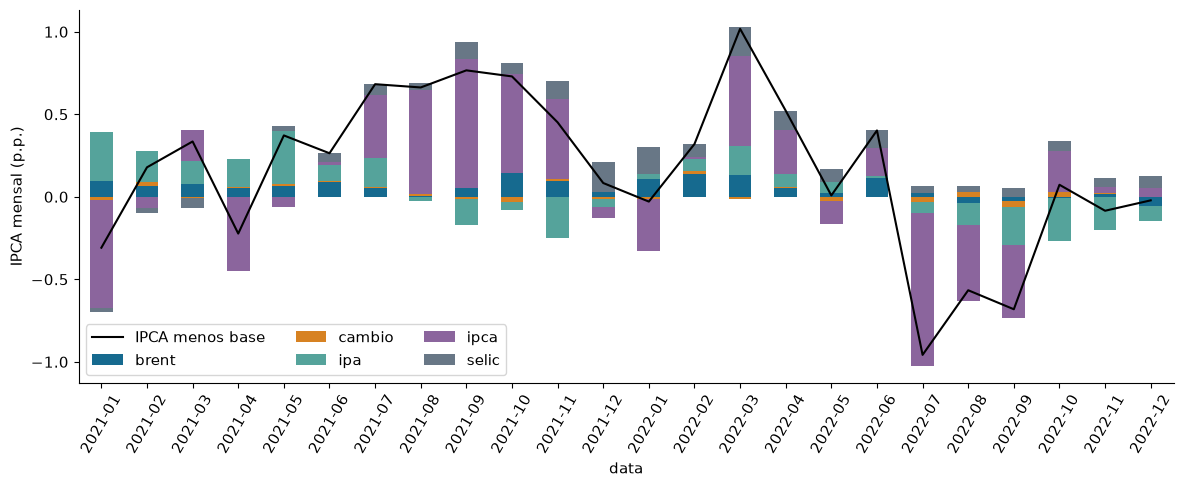

Erro máximo de reconstrução: 4.62e-14. Base: constante, calendário, pulsos e condições iniciais.


### 8. Verificação com dinâmica e impactos conhecidos

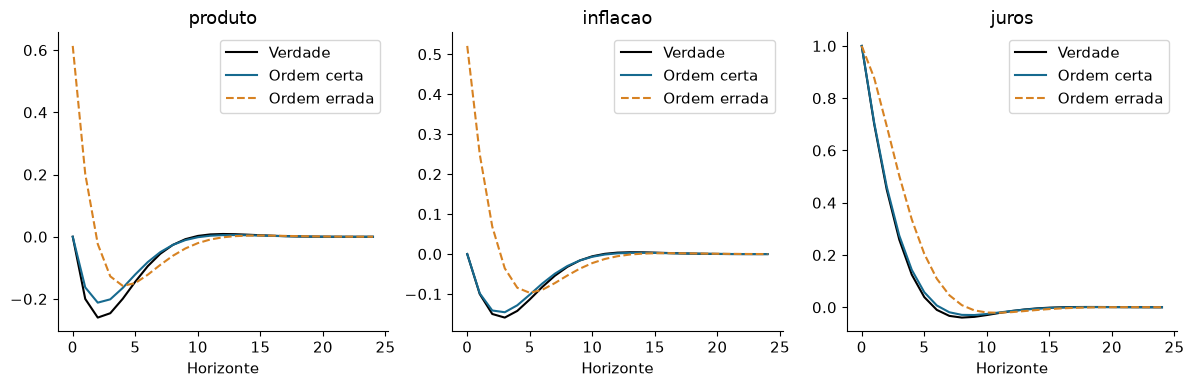

Ordem correta mais próxima nesta simulação: True


**08 simulacao**

,RMSE_IRF
certa,0.0116
errada,0.1328


### 9. Janela expansiva: VAR contra AR e passeio aleatório

**09 metricas**

,h,modelo,n,RMSE,MAE,DM_VAR_vs_modelo_p,CW_favor_VAR_p
0,1,VAR,116,0.3335,0.2509,NaN,NaN
1,1,AR,116,0.3466,0.2570,NaN,0.0003
2,1,RW,116,0.4112,0.3078,NaN,NaN
3,1,Sazonal,116,0.5060,0.3817,0.0045,NaN
4,12,VAR,105,0.3931,0.3042,NaN,NaN
5,12,AR,105,0.3882,0.2989,NaN,0.6596
6,12,RW,105,0.5197,0.3905,NaN,NaN
7,12,Sazonal,105,0.5197,0.3905,0.0301,NaN


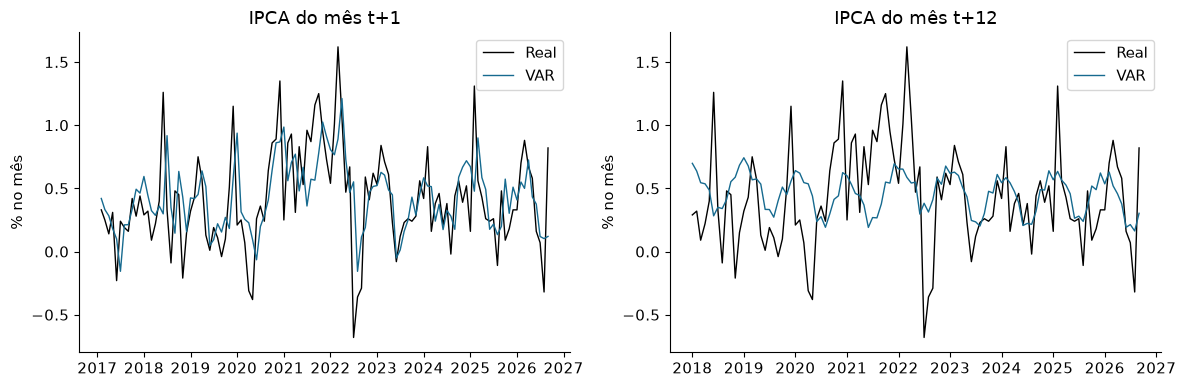

Pseudo fora da amostra: séries atuais/revisadas, sem reconstruir vintages/calendário de divulgação.
Sem dados posteriores à origem na estimação. DM: VAR vs sazonal, bilateral; CW: VAR vs AR, unilateral.
RW é referência descritiva. AR é aninhado no VAR; não interpretar DM entre eles.


### 10. Conclusão e arquivos para a apresentação

Brent: aumento na resposta acumulada do IPCA em h=12.
Cambio: redução na resposta acumulada do IPCA em h=12.
Antes/depois é associação entre regimes. Pandemia, tributos, composição de choques e 2023 também importam.
Tempo total: 30.5s. Resultados em resultados


In [6]:
# Complementos exigidos pelo desafio e síntese da execução atual.
complemento = var.completar_analise(dados, modelo)
resumo = var.salvar_resumo(dados, modelo, diagnostico, choques, complemento)
